# Clusterización — Segmentación de Clientes
## Dataset: **Credit Card Dataset for Clustering**


## Definición del problema y selección del algoritmo

### Definición del problema

Un emisor de tarjetas de crédito tiene cerca de 9.000 tarjetahabientes y quiere diseñar estrategias comerciales diferenciadas para ellos. Hoy trata a todos sus clientes de la misma manera, aunque no todos usan la tarjeta igual: algunos compran todos los meses y pagan el total, otros casi no la usan y otros la utilizan para sacar efectivo y arrastran deuda. Una misma campaña no sirve para todos: lo que motiva a un gran comprador no es lo que necesita un cliente endeudado.

El objetivo es **segmentar a los clientes según su comportamiento financiero**, usando las 17 variables disponibles (saldo, compras, avances en efectivo, pagos, cupo, frecuencias de uso, entre otras), para identificar grupos de clientes parecidos entre sí y distintos de los demás.

Es un problema de **aprendizaje no supervisado**: no existe una etiqueta que diga a qué segmento pertenece cada cliente, ni conocemos de antemano cuántos segmentos hay. No queremos predecir algo conocido, sino **descubrir una estructura** que está oculta en los datos. Por eso la técnica adecuada es el **clustering**.

### Selección del algoritmo: K-Means

Elegimos K-Means por cinco razones:

1. **Se ajusta al tipo de datos.** Las 17 variables son numéricas y, una vez escaladas, quedan en la misma escala. K-Means agrupa por distancia euclidiana, que funciona bien en este escenario.

2. **Sus resultados se pueden interpretar en lenguaje de negocio.** Cada grupo queda representado por un centroide, que es el cliente promedio del segmento. Eso permite describir cada grupo con cifras concretas ("compran 4 veces más que el promedio") y convertirlo en un perfil que el área comercial entiende.

3. **Permite controlar el número de segmentos.** Nosotros elegimos K. Esto es una ventaja para el negocio, porque un número pequeño de segmentos es más fácil de operar con campañas reales. Además, contamos con criterios objetivos para elegirlo: el método del codo y el coeficiente de silhouette.

4. **Es eficiente.** Con 7.608 clientes, K-Means converge en pocos segundos. Otros métodos, como el clustering jerárquico, deben calcular la distancia entre todos los pares de clientes (más de 28 millones de distancias), lo que los hace más lentos y costosos en memoria.

5. **Asigna a todos los clientes a un segmento.** A diferencia de DBSCAN, que deja por fuera a los clientes que considera "ruido", K-Means ubica a cada cliente en un grupo. Para el negocio esto es importante, porque cada tarjetahabiente necesita una estrategia.

### Limitaciones y cómo las manejamos

K-Means también tiene limitaciones, y las tuvimos en cuenta:

- **Es sensible a la escala de las variables:** sin ajuste, variables como el saldo (miles) dominarían sobre las frecuencias (0 a 1). Lo resolvimos estandarizando todas las variables.
- **Depende de los centroides iniciales:** según dónde arranque, puede llegar a soluciones distintas. Lo resolvimos ejecutando el algoritmo 10 veces (`n_init = 10`) y quedándonos con la mejor solución, y fijamos la semilla para que el resultado sea reproducible.
- **Hay que definir K de antemano:** lo elegimos combinando el método del codo y el silhouette.
- **Es sensible a valores extremos y supone grupos de forma compacta:** algunas variables tienen valores muy altos que pueden desplazar los centroides. No los eliminamos porque representan clientes reales y relevantes para el negocio, pero lo tenemos presente al interpretar los resultados.

Además de usar la implementación de sklearn, construimos K-Means desde cero con una clase propia, para comprender y validar su funcionamiento matemático y comparar ambos resultados.


Estructura:
1. Carga y exploración 
2. Limpieza y selección de variables + escalado  
3. Elección de K para K-Means (codo + silhouette)
4. Entrenamiento de K-Means
5. Algoritmo matemático
6. Visualización de clusters del algoritmo (PCA a 2D)
7. Perfilamiento de los grupos
8. Conclusiones



## 0. Semilla personal

In [1]:
cedula = 1152700501  # <-- número de cédula completo
import numpy as np
np.random.seed(cedula)
print(f"Semilla fijada en {cedula}")

Semilla fijada en 1152700501


## Diccionario de datos — `CC_GENERAL.csv`

| Variable | Descripción | Tipo | Rol |
|---|---|---|---|
| `CUST_ID` | Identificador único del cliente | Texto | Se descarta |
| `BALANCE` | Saldo disponible en la cuenta para hacer compras | Numérica | Feature |
| `BALANCE_FREQUENCY` | Qué tan frecuentemente se actualiza el balance (0 = poco, 1 = muy frecuente) | Numérica (0–1) | Feature |
| `PURCHASES` | Monto total de compras realizadas | Numérica | Feature |
| `ONEOFF_PURCHASES` | Monto de compras hechas de una sola vez (no a cuotas) | Numérica | Feature |
| `INSTALLMENTS_PURCHASES` | Monto de compras hechas a cuotas | Numérica | Feature |
| `CASH_ADVANCE` | Monto de adelantos de efectivo tomados con la tarjeta | Numérica | Feature |
| `PURCHASES_FREQUENCY` | Qué tan frecuentemente se hacen compras (0–1) | Numérica | Feature |
| `ONEOFF_PURCHASES_FREQUENCY` | Frecuencia de compras de una sola vez (0–1) | Numérica | Feature |
| `PURCHASES_INSTALLMENTS_FREQUENCY` | Frecuencia de compras a cuotas (0–1) | Numérica | Feature |
| `CASH_ADVANCE_FREQUENCY` | Frecuencia de adelantos de efectivo (0–1) | Numérica | Feature |
| `CASH_ADVANCE_TRX` | Número de transacciones de adelanto de efectivo | Numérica | Feature |
| `PURCHASES_TRX` | Número de transacciones de compra | Numérica | Feature |
| `CREDIT_LIMIT` | Límite de crédito de la tarjeta | Numérica | Feature (tiene nulos) |
| `PAYMENTS` | Monto total de pagos realizados por el cliente | Numérica | Feature |
| `MINIMUM_PAYMENTS` | Monto mínimo de pagos realizados | Numérica | Feature (tiene nulos) |
| `PRC_FULL_PAYMENT` | Porcentaje de veces que el cliente pagó el total de la deuda | Numérica (0–1) | Feature |
| `TENURE` | Antigüedad del cliente con la tarjeta, en meses | Numérica | Feature |

**No hay target** — es aprendizaje no supervisado. Todas las variables están en
escalas muy distintas (montos vs. frecuencias 0–1 vs. conteos) → **escalado
obligatorio** antes de clusterizar. `CREDIT_LIMIT` y `MINIMUM_PAYMENTS` tienen
nulos que se imputan en la sección 2.

## 1. Carga y exploración

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Ruta relativa apuntando al archivo CSV dentro de la carpeta 'data'
df = pd.read_csv("../data/CC_GENERAL.csv", low_memory=False)


print("Dimensiones:", df.shape)
df.head()

Dimensiones: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
df = df.sample(frac=0.85, random_state=cedula).reset_index(drop=True)
print("Dimensiones tras el muestreo:", df.shape)
df.info()

Dimensiones tras el muestreo: (7608, 18)
<class 'pandas.DataFrame'>
RangeIndex: 7608 entries, 0 to 7607
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           7608 non-null   str    
 1   BALANCE                           7608 non-null   float64
 2   BALANCE_FREQUENCY                 7608 non-null   float64
 3   PURCHASES                         7608 non-null   float64
 4   ONEOFF_PURCHASES                  7608 non-null   float64
 5   INSTALLMENTS_PURCHASES            7608 non-null   float64
 6   CASH_ADVANCE                      7608 non-null   float64
 7   PURCHASES_FREQUENCY               7608 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        7608 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  7608 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            7608 non-null   float64
 11  CASH_ADVANCE_TRX                  7608 

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BALANCE,7608.0,1578.68,2093.60,0.00,131.91,883.28,2065.47,18495.56
BALANCE_FREQUENCY,7608.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,7608.0,990.85,2104.95,0.00,34.68,359.98,1099.67,49039.57
ONEOFF_PURCHASES,7608.0,585.68,1640.42,0.00,0.00,34.98,572.12,40761.25
INSTALLMENTS_PURCHASES,7608.0,405.48,897.25,0.00,0.00,88.74,464.31,22500.00
CASH_ADVANCE,7608.0,991.75,2112.67,0.00,0.00,0.00,1135.27,47137.21
PURCHASES_FREQUENCY,7608.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,7608.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,7608.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,7608.0,0.14,0.20,0.00,0.00,0.00,0.25,1.50


Los montos (BALANCE, PURCHASES, PAYMENTS) tienen escalas de miles y máximos muy alejados de la mediana, mientras las frecuencias van de 0 a 1. Esto confirma la necesidad de escalar.

## 2. Limpieza y selección de variables + escalado

Este dataset tiene **nulos** (en `CREDIT_LIMIT` y `MINIMUM_PAYMENTS`) y variables
en **escalas muy dispares** (balances de miles frente a frecuencias entre 0 y 1).

### 2.1 Matriz de faltantes

<Axes: >

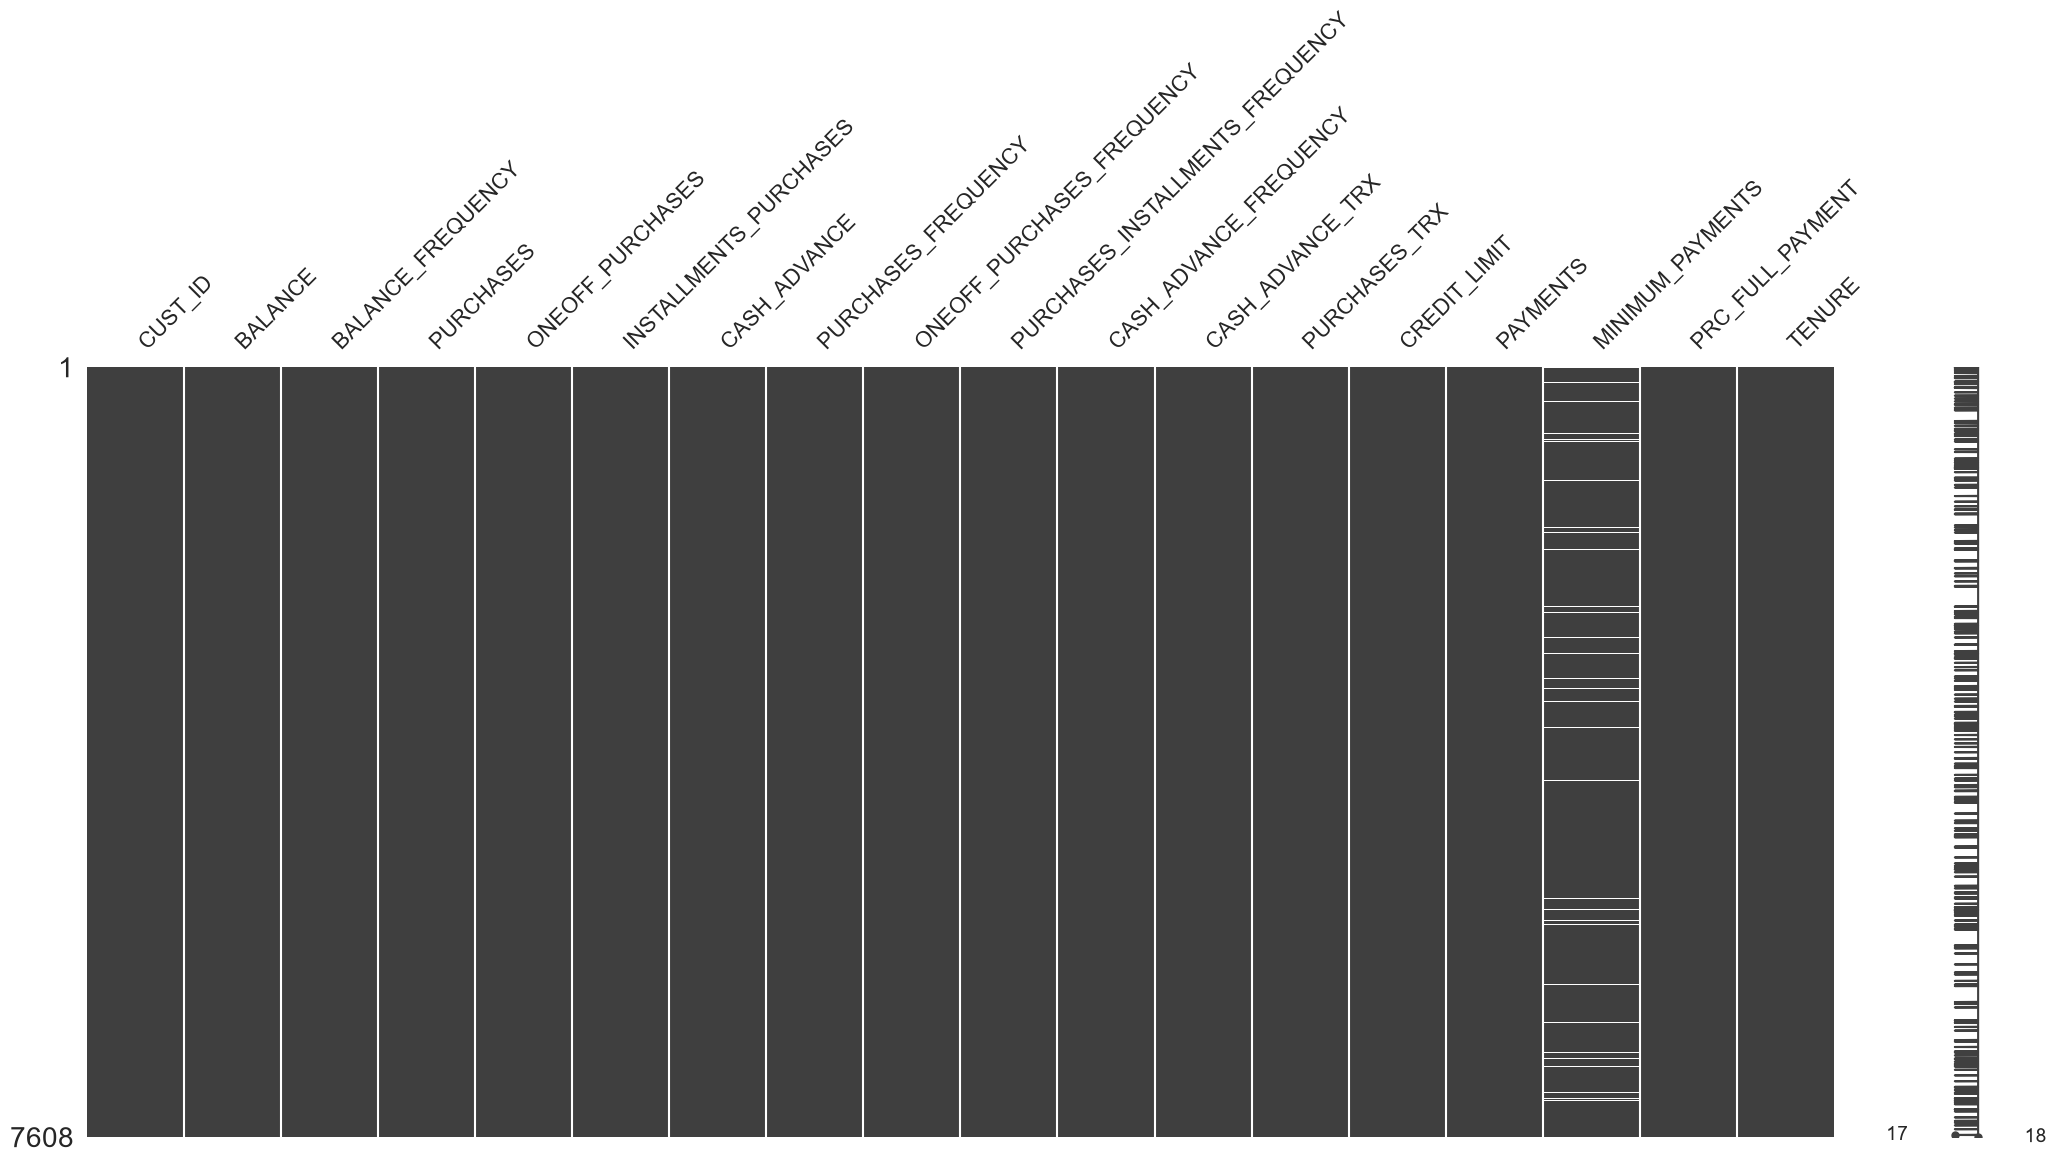

In [5]:
import missingno as msno

msno.matrix(df)

### 2.2 Tasa general de faltantes

In [6]:
# Tasa de faltantes: evaluación inicial de la calidad del dataset.
# Se calcula sobre la muestra del 85 % (semilla = cédula), antes de quitar CUST_ID e imputar.

# 1. Tasa global (sobre todas las celdas)
total_celdas = df.size                  # filas × columnas
total_nulos  = df.isna().sum().sum()    # 1er sum: por columna, 2do sum: total
tasa_global  = total_nulos / total_celdas * 100

print(f"Celdas totales: {total_celdas:,}")
print(f"Celdas faltantes: {total_nulos:,}")
print(f"Tasa global de faltantes: {tasa_global:.2f} %")

Celdas totales: 136,944
Celdas faltantes: 271
Tasa global de faltantes: 0.20 %


### 2.3 Gráficos para analizar la imputación en las dos variables con faltantes

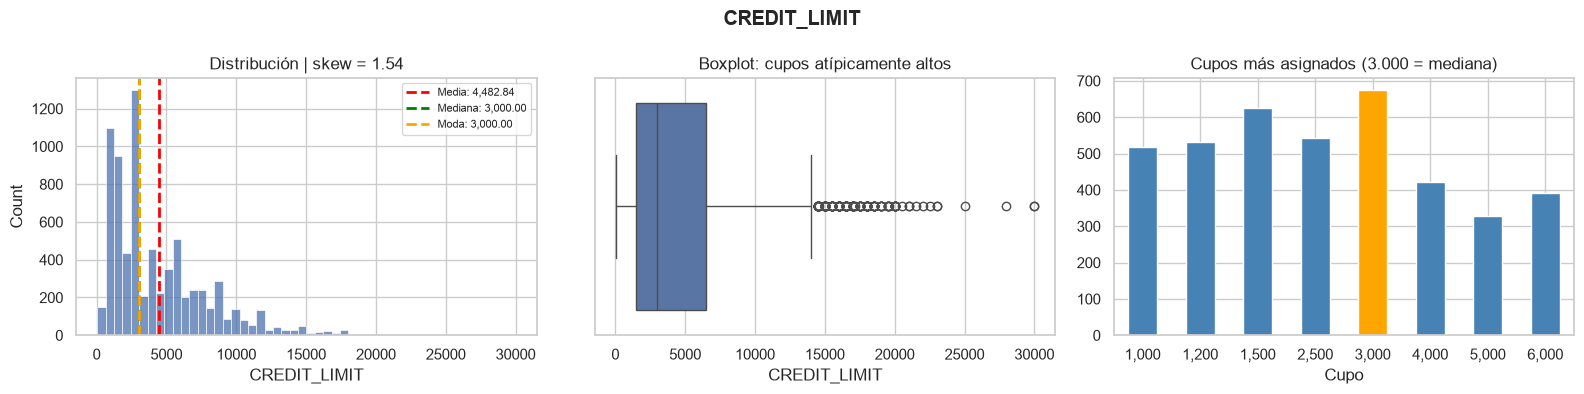

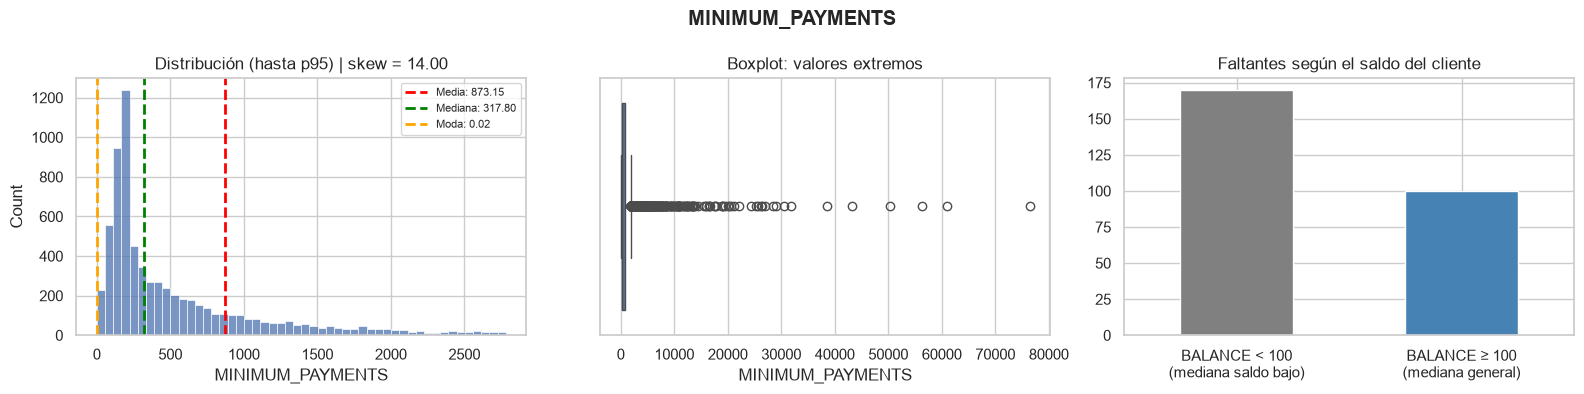

In [7]:
def lineas(ax, s):
    """Dibuja media, mediana y moda sobre un histograma."""
    for val, col, lab in [(s.mean(), 'red', 'Media'),
                          (s.median(), 'green', 'Mediana'),
                          (s.mode()[0], 'orange', 'Moda')]:
        ax.axvline(val, color=col, ls='--', lw=2, label=f'{lab}: {val:,.2f}')
    ax.legend(fontsize=8)

# ---------- CREDIT_LIMIT ----------
s = df['CREDIT_LIMIT'].dropna()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(s, bins=50, ax=ax[0]); lineas(ax[0], s)
ax[0].set_title(f'Distribución | skew = {s.skew():.2f}')

sns.boxplot(x=s, ax=ax[1]); ax[1].set_title('Boxplot: cupos atípicamente altos')

top = s.value_counts().head(8).sort_index()
top.index = top.index.astype(int).map('{:,}'.format)
top.plot.bar(ax=ax[2], rot=0,
             color=['orange' if i == '3,000' else 'steelblue' for i in top.index])
ax[2].set_title('Cupos más asignados (3.000 = mediana)'); ax[2].set_xlabel('Cupo')

plt.suptitle('CREDIT_LIMIT', fontweight='bold'); plt.tight_layout(); plt.show()

# ---------- MINIMUM_PAYMENTS ----------
s = df['MINIMUM_PAYMENTS'].dropna()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(s[s <= s.quantile(0.95)], bins=50, ax=ax[0]); lineas(ax[0], s)
ax[0].set_title(f'Distribución (hasta p95) | skew = {s.skew():.2f}')

sns.boxplot(x=s, ax=ax[1]); ax[1].set_title('Boxplot: valores extremos')

falt = df[df['MINIMUM_PAYMENTS'].isna()]
pd.Series({'BALANCE < 100\n(mediana saldo bajo)': (falt['BALANCE'] < 100).sum(),
           'BALANCE ≥ 100\n(mediana general)':    (falt['BALANCE'] >= 100).sum()}
         ).plot.bar(ax=ax[2], color=['gray', 'steelblue'], rot=0)
ax[2].set_title('Faltantes según el saldo del cliente')

plt.suptitle('MINIMUM_PAYMENTS', fontweight='bold'); plt.tight_layout(); plt.show()

CREDIT_LIMIT: mediana

Solo un cliente no tiene cupo registrado, así que el efecto es mínimo, pero quisimos asignarle un valor realista. La mayoría de clientes tiene cupos bajos y unos pocos llegan hasta 30.000, lo que sube la media a 4.483, un cupo que no describe al cliente común. La mediana, 3.000, coincide con el cupo que más asigna el banco, por eso fue nuestra elección.

MINIMUM_PAYMENTS: mediana según el saldo

La media no sirve porque unos pocos pagos muy altos la inflan a casi el triple de la mediana, y la moda tampoco porque casi ningún valor se repite. Al revisar a los 270 clientes sin dato encontramos que casi no tienen deuda: su saldo típico es 19, frente a 926 del resto. Tiene sentido que el banco no les haya generado una cuota mínima. Ponerles la mediana general (318) sería darles una cuota mayor que lo que deben, así que a los de saldo bajo les asignamos la mediana de clientes parecidos (126) y al resto la mediana general.

### 2.4 Quitar el identificador y tratar nulos
`CUST_ID` es un identificador (no aporta al clustering). Los nulos se imputan según lo justificado en 2.3: `CREDIT_LIMIT` con la mediana y `MINIMUM_PAYMENTS` con la mediana según el saldo.

In [8]:
df = df.drop(columns=["CUST_ID"])
print("Nulos antes:", df.isna().sum().sum())

# CREDIT_LIMIT: mediana
df["CREDIT_LIMIT"] = df["CREDIT_LIMIT"].fillna(df["CREDIT_LIMIT"].median())

# MINIMUM_PAYMENTS: mediana según el saldo
# (las medianas se calculan antes de imputar para no contaminarlas)
med_general    = df["MINIMUM_PAYMENTS"].median()
med_saldo_bajo = df.loc[df["BALANCE"] < 100, "MINIMUM_PAYMENTS"].median()

faltante   = df["MINIMUM_PAYMENTS"].isna()
saldo_bajo = df["BALANCE"] < 100

df.loc[faltante & saldo_bajo,  "MINIMUM_PAYMENTS"] = med_saldo_bajo
df.loc[faltante & ~saldo_bajo, "MINIMUM_PAYMENTS"] = med_general

print(f"Mediana saldo bajo: {med_saldo_bajo:.2f} -> {(faltante & saldo_bajo).sum()} clientes")
print(f"Mediana general:    {med_general:.2f} -> {(faltante & ~saldo_bajo).sum()} clientes")
print("Nulos después:", df.isna().sum().sum())

Nulos antes: 271
Mediana saldo bajo: 126.40 -> 170 clientes
Mediana general:    317.80 -> 100 clientes
Nulos después: 0


### 2.5 Se validan nuevamente los nulos

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7608 entries, 0 to 7607
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   BALANCE                           7608 non-null   float64
 1   BALANCE_FREQUENCY                 7608 non-null   float64
 2   PURCHASES                         7608 non-null   float64
 3   ONEOFF_PURCHASES                  7608 non-null   float64
 4   INSTALLMENTS_PURCHASES            7608 non-null   float64
 5   CASH_ADVANCE                      7608 non-null   float64
 6   PURCHASES_FREQUENCY               7608 non-null   float64
 7   ONEOFF_PURCHASES_FREQUENCY        7608 non-null   float64
 8   PURCHASES_INSTALLMENTS_FREQUENCY  7608 non-null   float64
 9   CASH_ADVANCE_FREQUENCY            7608 non-null   float64
 10  CASH_ADVANCE_TRX                  7608 non-null   int64  
 11  PURCHASES_TRX                     7608 non-null   int64  
 12  CREDIT_LIMIT     

### 2.6 Escalado
Los algoritmos de clustering usan distancias euclídeas, así que
**estandarizamos todas las variables** con `StandardScaler` (si no, `BALANCE`
dominaría sobre las frecuencias).

In [10]:
from sklearn.preprocessing import StandardScaler

X = df.copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Shape escalado:", X_scaled.shape)
print("Media≈0:", np.round(X_scaled.mean(), 3), "| std≈1:", np.round(X_scaled.std(), 3))

Shape escalado: (7608, 17)
Media≈0: -0.0 | std≈1: 1.0


Variables independientes (X): las 17 variables de comportamiento escaladas. Variable dependiente (Y): no existe, porque es aprendizaje no supervisado; la salida del modelo es el cluster asignado a cada cliente.

## 3. Elección de K para K-Means

Combinamos dos criterios:
- **Método del codo (inercia):** buscamos el "codo" donde añadir clusters deja
  de reducir mucho la inercia.
- **Silhouette score:** mide qué tan bien separados están los clusters
  (más alto = mejor).

Usamos `random_state=cedula` y `n_init=10`.

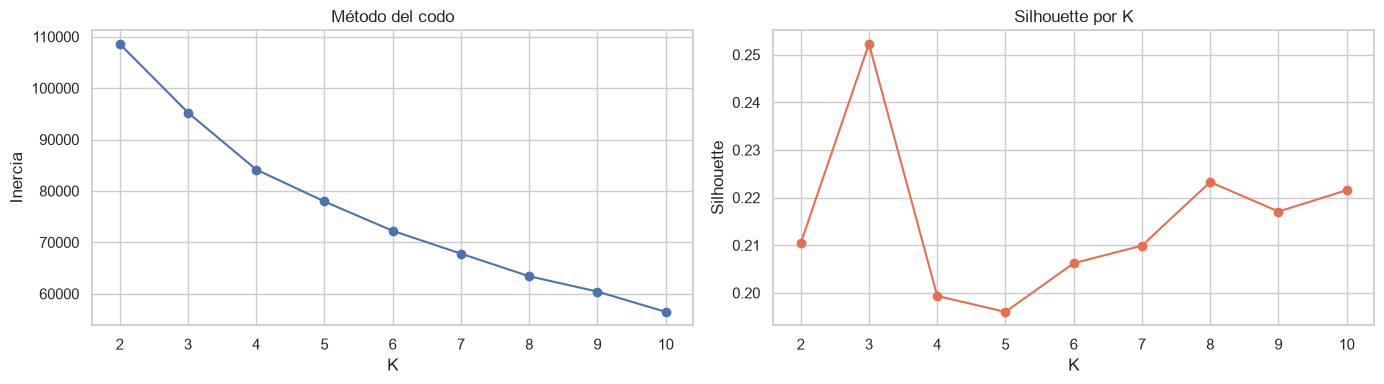

 K    Inercia  Silhouette  Reducción inercia (%)
 2 108607.568       0.210                    NaN
 3  95243.149       0.252                 12.305
 4  84162.925       0.199                 11.634
 5  77950.526       0.196                  7.381
 6  72243.474       0.206                  7.321
 7  67803.943       0.210                  6.145
 8  63406.249       0.223                  6.486
 9  60427.282       0.217                  4.698
10  56479.194       0.222                  6.534

K con mejor silhouette: 3


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, sils, Ks = [], [], range(2, 11)
for k in Ks:
    km = KMeans(n_clusters=k, random_state=cedula, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(Ks), inertias, "o-"); axes[0].set_title("Método del codo")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inercia")
axes[1].plot(list(Ks), sils, "o-", color="#e76f51"); axes[1].set_title("Silhouette por K")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

tabla_k = pd.DataFrame({"K": list(Ks), "Inercia": inertias, "Silhouette": sils})
tabla_k["Reducción inercia (%)"] = -tabla_k["Inercia"].pct_change() * 100
print(tabla_k.round(3).to_string(index=False))

best_k = list(Ks)[int(np.argmax(sils))]
print("\nK con mejor silhouette:", best_k)

**Lectura:**

- El **silhouette** tiene su máximo en **K = 3** (≈ 0,252). Con K = 4 y K = 5 cae
  a ≈ 0,20, y aunque vuelve a subir un poco desde K = 7, nunca alcanza el valor
  de K = 3.
- En el **codo**, las dos mayores caídas de inercia son al pasar de 2 a 3 (≈ 12 %)
  y de 3 a 4 (≈ 12 %). Desde K = 5 cada cluster extra reduce menos del 8 %, así
  que la curva se aplana a partir de K = 3–4.
- Los valores de silhouette son **moderados** (0,20–0,25) en todos los K, lo
  esperable con 17 variables de comportamiento que se solapan: los clientes no
  forman "islas" perfectamente separadas.

Por eso fijamos **K = 3** para K-Means.

## 4. Entrenamiento de K-Means

Entrenamos K-Means con K = 3 (random_state=cedula, n_init=10), guardamos las etiquetas en la columna Cluster_KMeans y revisamos cuántos clientes quedaron en cada cluster.

In [12]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=cedula, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)
df["Cluster_KMeans"] = labels_kmeans

conteo = df["Cluster_KMeans"].value_counts().sort_index()
porcentaje = df["Cluster_KMeans"].value_counts(normalize=True).sort_index() * 100

print("Clientes por cluster (K-Means):")
print(pd.DataFrame({"Clientes": conteo, "% de la base": porcentaje.round(2)}))

Clientes por cluster (K-Means):
                Clientes  % de la base
Cluster_KMeans                        
0                   5235         68.81
1                   1027         13.50
2                   1346         17.69


K-Means reparte la base en **un grupo mayoritario (~69 %)** y **dos grupos más
pequeños (~13 % y ~18 %)**. Veremos en el perfilamiento qué los
distingue.

### 4.1 Propuesta alternativa: K = 4 en K-Means


In [13]:
k_alt = 4
kmeans_alt = KMeans(n_clusters=k_alt, random_state=cedula, n_init=10)
labels_kmeans_alt = kmeans_alt.fit_predict(X_scaled)
df["Cluster_KMeans_K4"] = labels_kmeans_alt

conteo_alt = df["Cluster_KMeans_K4"].value_counts().sort_index()
porcentaje_alt = df["Cluster_KMeans_K4"].value_counts(normalize=True).sort_index() * 100

print("Clientes por cluster (K-Means, K=4):")
print(pd.DataFrame({"Clientes": conteo_alt, "% de la base": porcentaje_alt.round(2)}))

print("\nSilhouette K=4:", round(silhouette_score(X_scaled, labels_kmeans_alt), 3))

print("\nCruce K=3 (filas) vs. K=4 (columnas) en K-Means:")
print(pd.crosstab(df["Cluster_KMeans"], df["Cluster_KMeans_K4"]))

Clientes por cluster (K-Means, K=4):
                   Clientes  % de la base
Cluster_KMeans_K4                        
0                       350          4.60
1                      1026         13.49
2                      3394         44.61
3                      2838         37.30

Silhouette K=4: 0.199

Cruce K=3 (filas) vs. K=4 (columnas) en K-Means:
Cluster_KMeans_K4    0     1     2     3
Cluster_KMeans                          
0                    0     1  3076  2158
1                  349    24     2   652
2                    1  1001   316    28


Lectura (K = 4): con K = 4, el grupo mayoritario de K = 3 (5.235 clientes) se divide en dos subgrupos de 3.076 y 2.158, que era lo que buscábamos. Sin embargo, el cruce muestra que K = 4 no solo divide ese grupo: también separa uno de los grupos pequeños y forma un segmento de apenas 350 clientes (4,6 %), demasiado reducido para justificar una estrategia comercial propia. Además, el silhouette baja de 0,25 a 0,20, lo que indica grupos menos definidos. Como K = 3 ofrece la mejor separación y tres segmentos son más claros de interpretar y de operar para el área comercial, mantenemos K = 3 para el resto del análisis.


## 5. K-Means implementado desde cero

Construimos K-Means con una clase propia, sin usar `sklearn.cluster.KMeans`.

### Fundamento matemático

**Notación:**
- $n$ = número de clientes (7.608) y $p$ = número de variables (17).
- $x_i$ = vector del cliente $i$ con sus 17 variables escaladas.
- $K$ = número de clusters (3) y $\mu_j$ = centroide del cluster $j$.
- $c_i$ = cluster asignado al cliente $i$.

**1. Distancia euclidiana al cuadrado** entre un cliente y un centroide:

$$d^2(x_i, \mu_j) = \sum_{v=1}^{p} (x_{iv} - \mu_{jv})^2$$

Se resta variable por variable, se eleva al cuadrado y se suma. Usamos la distancia al cuadrado porque no cambia cuál centroide es el más cercano y evita calcular raíces.

**2. Asignación:** cada cliente va al centroide más cercano:

$$c_i = \arg\min_{j \in \{1,\dots,K\}} \; d^2(x_i, \mu_j)$$

**3. Actualización:** cada centroide pasa a ser el promedio de los clientes de su cluster $C_j$:

$$\mu_j = \frac{1}{|C_j|} \sum_{x_i \in C_j} x_i$$

**4. Inercia (función objetivo que K-Means minimiza):**

$$J = \sum_{i=1}^{n} d^2(x_i, \mu_{c_i})$$

Es la suma de las distancias al cuadrado de cada cliente a su propio centroide. Mientras más pequeña, más compactos son los grupos.

**5. Criterio de convergencia:** el algoritmo se detiene cuando los centroides casi no se mueven entre una iteración $t$ y la siguiente:

$$\sum_{j=1}^{K} \lVert \mu_j^{(t+1)} - \mu_j^{(t)} \rVert^2 < \text{tol} \quad (\text{tol} = 10^{-4})$$

o cuando se alcanza el máximo de iteraciones (300).

**6. Varias corridas:** el resultado depende de los centroides iniciales (elegidos al azar entre los clientes). Se ejecutan `n_init = 10` corridas y se conserva la de menor inercia $J$.


### 5.1 Implementación de la clase `KMeansManual`

Definimos la clase con su constructor y los métodos que reproducen cada paso del algoritmo: medir distancias, ubicar los centroides iniciales, asignar clientes, actualizar centroides, calcular la inercia y entrenar con varias corridas (`n_init`) quedándonos con la de menor inercia.

In [14]:
class KMeansManual:
    """K-Means implementado desde cero."""

    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, n_init=10, random_state=None):
        # Hiperparámetros del modelo
        self.n_clusters = n_clusters        # K: número de clusters
        self.max_iter = max_iter            # máximo de iteraciones por corrida
        self.tol = tol                      # umbral de convergencia de los centroides
        self.n_init = n_init                # número de corridas con distinta inicialización
        self.rng = np.random.default_rng(random_state)  # generador aleatorio con la semilla

        # Atributos que se llenan al entrenar
        self.centroides_ = None   # posición final de los centroides
        self.labels_ = None       # cluster asignado a cada cliente
        self.inertia_ = None      # inercia de la mejor solución
        self.n_iter_ = None       # iteraciones que necesitó la mejor corrida
        self.historial_ = None    # inercia en cada iteración de la mejor corrida

    def _distancias_cuadradas(self, X, centroides):
        """Distancia euclidiana al cuadrado de cada cliente a cada centroide.
        Devuelve una matriz de (n_clientes x n_centroides)."""
        diferencias = X[:, np.newaxis, :] - centroides[np.newaxis, :, :]
        return (diferencias ** 2).sum(axis=2)

    def _inicializar_centroides(self, X):
        """Elige K clientes al azar (sin repetir) como centroides iniciales."""
        indices = self.rng.choice(X.shape[0], size=self.n_clusters, replace=False)
        return X[indices].copy(), indices

    def _asignar(self, X, centroides):
        """Asigna cada cliente al centroide más cercano (columna con menor distancia)."""
        return self._distancias_cuadradas(X, centroides).argmin(axis=1)

    def _actualizar(self, X, labels, centroides_previos):
        """Recalcula cada centroide como el promedio de los clientes de su cluster."""
        nuevos = np.empty_like(centroides_previos)
        for j in range(self.n_clusters):
            clientes_del_cluster = X[labels == j]
            if len(clientes_del_cluster) > 0:
                nuevos[j] = clientes_del_cluster.mean(axis=0)  # promedio de las 17 variables
            else:
                nuevos[j] = X[self.rng.integers(X.shape[0])]   # cluster vacío: se reubica al azar
        return nuevos

    def _inercia(self, X, labels, centroides):
        """Suma de distancias al cuadrado de cada cliente a su propio centroide."""
        return ((X - centroides[labels]) ** 2).sum()

    def _una_corrida(self, X):
        """Ejecuta el algoritmo completo una vez: asigna y actualiza hasta que los centroides convergen."""
        centroides, _ = self._inicializar_centroides(X)
        historial = []

        for iteracion in range(1, self.max_iter + 1):
            labels = self._asignar(X, centroides)                  # 1. asignar clientes
            historial.append(self._inercia(X, labels, centroides)) #    registrar la inercia de la iteración
            nuevos = self._actualizar(X, labels, centroides)       # 2. actualizar centroides
            movimiento = ((nuevos - centroides) ** 2).sum()        # 3. medir el desplazamiento
            centroides = nuevos
            if movimiento < self.tol:                              # 4. convergencia: terminar
                break

        labels = self._asignar(X, centroides)
        inercia = self._inercia(X, labels, centroides)
        historial.append(inercia)
        return centroides, labels, inercia, iteracion, historial

    def fit(self, X):
        """Entrena el modelo: ejecuta n_init corridas y conserva la de menor inercia."""
        X = np.asarray(X, dtype=float)
        mejor = None
        self.inercias_corridas_ = []          # inercia final de cada corrida

        for _ in range(self.n_init):
            resultado = self._una_corrida(X)
            self.inercias_corridas_.append(resultado[2])
            if mejor is None or resultado[2] < mejor[2]:   # se conserva la corrida con menor inercia
                mejor = resultado

        self.centroides_, self.labels_, self.inertia_, self.n_iter_, self.historial_ = mejor
        return self

    def predict(self, X):
        """Asigna clientes (nuevos o existentes) al centroide más cercano del modelo entrenado."""
        return self._asignar(np.asarray(X, dtype=float), self.centroides_)

    def fit_predict(self, X):
        """Entrena el modelo y devuelve el cluster de cada cliente."""
        return self.fit(X).labels_

### 5.2 Entrenamiento con K = 3

Entrenamos nuestra implementación con K = 3, 10 corridas (`n_init = 10`) y la cédula como semilla. Revisamos la inercia final de cada corrida, la mejor solución encontrada y cómo baja la inercia en cada vuelta hasta que los centroides dejan de moverse (convergencia).

Inercia final de cada una de las 10 corridas:
  Corrida  1: 95,850.68
  Corrida  2: 95,241.65
  Corrida  3: 95,611.63
  Corrida  4: 95,611.63
  Corrida  5: 95,611.91
  Corrida  6: 95,611.63
  Corrida  7: 95,243.18
  Corrida  8: 95,242.08
  Corrida  9: 95,612.22
  Corrida 10: 95,243.02

Mejor inercia: 95,241.65
Vueltas que necesitó la mejor corrida: 15
Clientes por grupo: [1329 5208 1071]


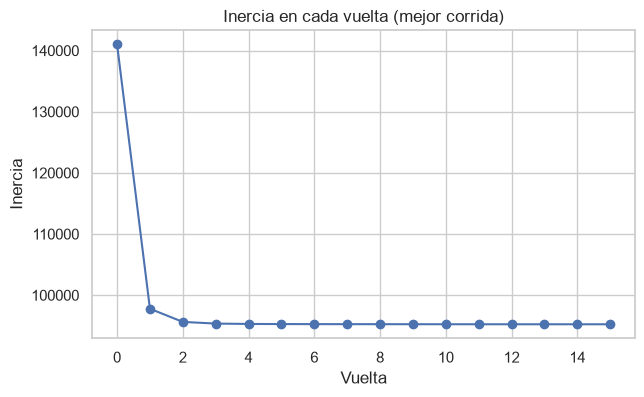

In [15]:
km_manual = KMeansManual(n_clusters=3, n_init=10, random_state=cedula)
labels_manual = km_manual.fit_predict(X_scaled)

print("Inercia final de cada una de las 10 corridas:")
for i, inercia in enumerate(km_manual.inercias_corridas_, start=1):
    print(f"  Corrida {i:2d}: {inercia:,.2f}")

print(f"\nMejor inercia: {km_manual.inertia_:,.2f}")
print(f"Vueltas que necesitó la mejor corrida: {km_manual.n_iter_}")
print("Clientes por grupo:", np.bincount(labels_manual))

# Cómo bajó la inercia en la mejor corrida
plt.figure(figsize=(7, 4))
plt.plot(range(len(km_manual.historial_)), km_manual.historial_, "o-")
plt.title("Inercia en cada vuelta (mejor corrida)")
plt.xlabel("Vuelta"); plt.ylabel("Inercia")
plt.show()

**Lectura:** no todas las corridas llegan al mismo resultado: según dónde arranquen los centroides, la inercia final va de 95.241,65 a 95.850,68. La primera corrida fue la peor, así que si hubiéramos ejecutado el algoritmo una sola vez nos habríamos quedado con una solución de menor calidad. Por eso se usan varias corridas (`n_init = 10`) y se conserva la de menor inercia. La mejor corrida convergió en 15 vueltas. El gráfico muestra que la inercia cae bruscamente en las dos primeras vueltas (de unos 141.000 a 96.000) y luego se estabiliza: los centroides encuentran su lugar rápido y después solo hacen ajustes finos hasta quedarse quietos.

### 5.3 Comparación con K-Means de sklearn

In [16]:
from sklearn.metrics import adjusted_rand_score

# 1. Tabla cruzada: ¿qué grupo nuestro coincide con cada grupo de sklearn?
cruce = pd.crosstab(labels_kmeans, labels_manual,
                    rownames=["sklearn"], colnames=["Propio"])
print("Cruce ANTES de alinear:")
print(cruce)

# 2. Renombrar nuestros grupos con el número del grupo de sklearn que más coincide
mapeo = {int(grupo): int(cruce[grupo].idxmax()) for grupo in cruce.columns}
labels_manual_alineado = pd.Series(labels_manual).map(mapeo).values
print("\nRenombre de grupos (propio -> sklearn):", mapeo)

# 3. Comparar métricas
comparacion = pd.DataFrame({
    "sklearn": [kmeans.inertia_,
                silhouette_score(X_scaled, labels_kmeans)],
    "Propio":  [km_manual.inertia_,
                silhouette_score(X_scaled, labels_manual_alineado)]
}, index=["Inercia", "Silhouette"])
print("\nMétricas:")
print(comparacion.round(4))

# 4. ¿Cuántos clientes quedaron en el mismo grupo?
iguales = (labels_kmeans == labels_manual_alineado)
print(f"\nClientes en el mismo grupo: {iguales.sum():,} de {len(iguales):,} ({iguales.mean()*100:.2f} %)")
print(f"Clientes en distinto grupo: {(~iguales).sum()}")
print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(labels_kmeans, labels_manual):.3f}")

# 5. Cruce después de alinear
print("\nCruce DESPUÉS de alinear:")
print(pd.crosstab(labels_kmeans, labels_manual_alineado,
                  rownames=["sklearn"], colnames=["Propio"]))

# Guardamos el resultado en el DataFrame para usarlo en el perfilamiento
df["Cluster_Manual"] = labels_manual_alineado

Cruce ANTES de alinear:
Propio      0     1     2
sklearn                  
0           0  5191    44
1           1     0  1026
2        1328    17     1

Renombre de grupos (propio -> sklearn): {0: 2, 1: 0, 2: 1}

Métricas:
               sklearn      Propio
Inercia     95243.1487  95241.6503
Silhouette      0.2523      0.2519

Clientes en el mismo grupo: 7,545 de 7,608 (99.17 %)
Clientes en distinto grupo: 63
Adjusted Rand Index (ARI): 0.973

Cruce DESPUÉS de alinear:
Propio      0     1     2
sklearn                  
0        5191    44     0
1           0  1026     1
2          17     1  1328


**Lectura:** nuestra implementación llega prácticamente a la misma solución que sklearn. La inercia es casi idéntica (95.241,65 frente a 95.243,15; la nuestra incluso es un poco menor) y el silhouette también (0,2519 frente a 0,2523). Como los números de los grupos son arbitrarios, primero alineamos nuestros grupos con los de sklearn. Hecho eso, 7.545 de los 7.608 clientes (99,17 %) quedan en el mismo grupo en ambos modelos, y el ARI de 0,973 confirma que las dos segmentaciones son prácticamente iguales. Las diferencias se concentran en 63 clientes, sobre todo 44 que sklearn ubica en el grupo 0 y nosotros en el grupo 1. Son clientes de frontera, casi a la misma distancia de dos centroides, que pueden caer en uno u otro grupo según el punto de partida del algoritmo. Esto valida que la implementación desde cero es correcta.

## 6. Visualización de clusters con PCA (2D)

Reducimos las 17 variables a 2 componentes principales para visualizar los grupos. PCA se usa solo para graficar: los clusters se formaron con las 17 variables.

Información conservada: PC1 = 27.1 %, PC2 = 20.5 %, total = 47.5 %


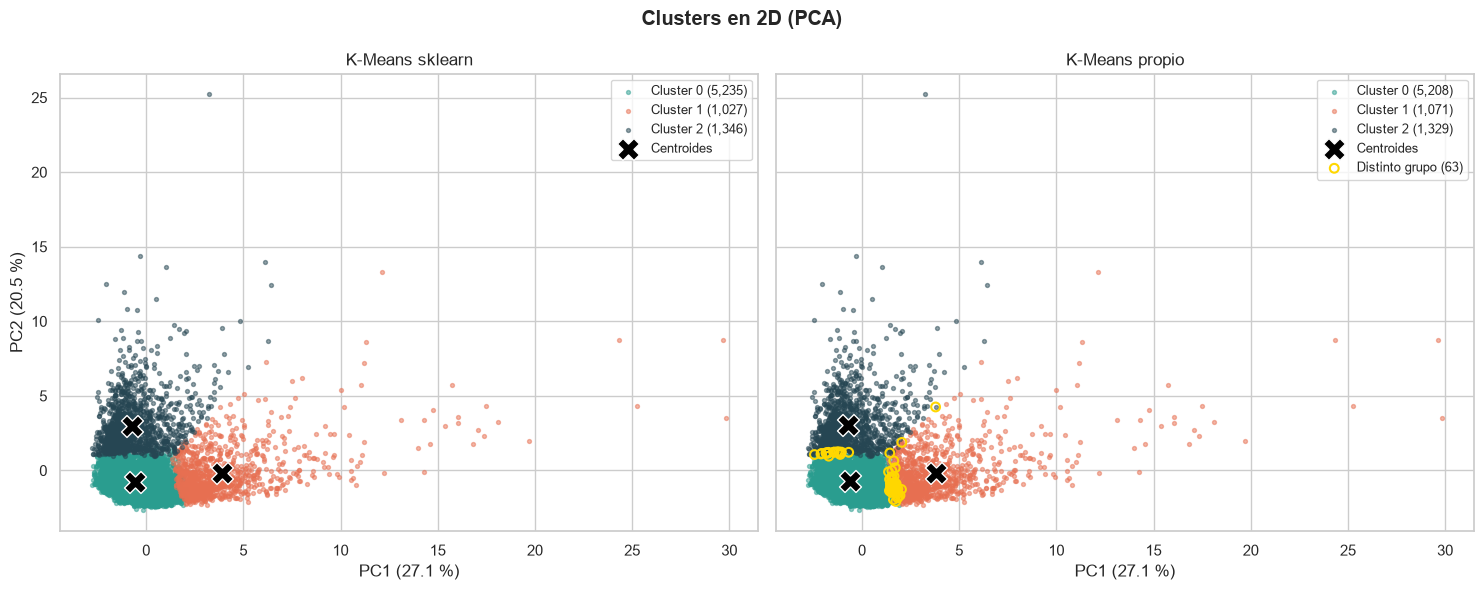

In [17]:
from sklearn.decomposition import PCA

# 1. Reducir de 17 a 2 dimensiones
pca = PCA(n_components=2, random_state=cedula)
X_pca = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_ * 100
print(f"Información conservada: PC1 = {var[0]:.1f} %, PC2 = {var[1]:.1f} %, total = {var.sum():.1f} %")

# 2. Proyectar los centroides al mismo plano 2D
#    (los del modelo propio se reordenan según el renombre hecho en 5.3)
inverso = {v: k for k, v in mapeo.items()}
cent_sklearn = pca.transform(kmeans.cluster_centers_)
cent_propio  = pca.transform(km_manual.centroides_[[inverso[0], inverso[1], inverso[2]]])

# 3. Graficar lado a lado
colores = ["#2a9d8f", "#e76f51", "#264653"]
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for eje, labels, centroides, titulo in [
        (ax[0], labels_kmeans,          cent_sklearn, "K-Means sklearn"),
        (ax[1], labels_manual_alineado, cent_propio,  "K-Means propio")]:
    for g in range(3):
        eje.scatter(X_pca[labels == g, 0], X_pca[labels == g, 1], s=8, alpha=0.5,
                    color=colores[g], label=f"Cluster {g} ({(labels == g).sum():,})")
    eje.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=250,
                color="black", edgecolor="white", label="Centroides")
    eje.set_title(titulo)
    eje.set_xlabel(f"PC1 ({var[0]:.1f} %)")
    eje.legend(fontsize=9)

ax[0].set_ylabel(f"PC2 ({var[1]:.1f} %)")

# 4. Marcar los clientes que quedaron en distinto grupo
diferentes = labels_kmeans != labels_manual_alineado
ax[1].scatter(X_pca[diferentes, 0], X_pca[diferentes, 1], s=40, facecolors="none",
              edgecolors="gold", linewidths=1.5, label=f"Distinto grupo ({diferentes.sum()})")
ax[1].legend(fontsize=9)

plt.suptitle("Clusters en 2D (PCA)", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** las dos primeras componentes conservan el 47,5 % de la información (27,1 % y 20,5 %), suficiente para ver la estructura general de los grupos. Los gráficos de sklearn y de nuestra implementación son prácticamente idénticos: mismos grupos y centroides en la misma posición. Los 63 clientes que quedaron en distinto grupo (círculos amarillos) se ubican justo en la frontera entre dos clusters, lo que confirma que son clientes de borde y no errores del algoritmo. PC1 refleja la actividad de compras y PC2 el uso de avances en efectivo y el saldo, lo que anticipa tres perfiles: uso bajo (cluster 0), grandes compradores (cluster 1) y usuarios de avances en efectivo (cluster 2).

## 7. Perfilamiento de los clusters

Calculamos el promedio de cada variable por cluster y lo comparamos con el promedio general de la base, para describir qué caracteriza a cada grupo. Perfilamos los clusters de nuestra implementación propia (`Cluster_Manual`).

### Lectura del perfilamiento

- **Cluster 0 (~68,5 %, ≈ 5.208 clientes): uso bajo.** Está por debajo del promedio
  en casi todo: saldo ≈ 815, compras ≈ 492, avances ≈ 343 y cupo ≈ 3.253 (el más
  bajo, 0,7 veces el promedio). Compran de vez en cuando (`PURCHASES_FREQUENCY` ≈ 0,46)
  y en montos pequeños. Pagan el total con una frecuencia similar al promedio
  (`PRC_FULL_PAYMENT` ≈ 0,15).
- **Cluster 1 (~14,1 %, ≈ 1.071 clientes): grandes compradores.** Compras ≈ 4.156
  (**4,2 veces** el promedio), unas 56 transacciones, frecuencia de compra ≈ 0,95
  (compran casi todos los meses), tanto de contado como a cuotas. Tienen el cupo
  más alto (≈ 7.562), casi no usan avances (≈ 460, menos de la mitad del promedio)
  y son los que **más pagan el total** (`PRC_FULL_PAYMENT` ≈ 0,29, 1,9 veces el promedio).
- **Cluster 2 (~17,5 %, ≈ 1.329 clientes): usuarios de avances en efectivo.**
  Avances ≈ 3.964 (**4 veces** el promedio, unas 13 transacciones), el **saldo más
  alto** (≈ 4.082, 2,6 veces el promedio), compras muy bajas (0,4 veces el promedio)
  y casi nunca pagan el total (`PRC_FULL_PAYMENT` ≈ 0,03). Sus pagos mínimos son los
  más altos (≈ 1.737, 2 veces el promedio): arrastran deuda.

`TENURE` y `BALANCE_FREQUENCY` son prácticamente iguales en los 3 grupos (entre
0,95 y 1,12 veces el promedio), así que no los diferencian.

**Comparación con sklearn:** los perfiles son los mismos en ambos modelos y las
cifras apenas cambian. Por ejemplo, las compras del cluster 1 son 4.156 en nuestra
implementación frente a 4.257 en sklearn, y los avances del cluster 2 son 3.964
frente a 3.932. Las pequeñas diferencias se deben a los 63 clientes de frontera
que cambian de grupo.

## 8. Conclusiones


### 8.1 Conclusiones de negocio

La segmentación identificó tres perfiles claramente diferenciados, cada uno con una estrategia comercial propia:

- **Uso bajo (68,5 %):** la mayoría de la base usa poco la tarjeta. La oportunidad es **activarlos** con beneficios por compras, cashback o recordatorios de uso.
- **Grandes compradores (14,1 %):** compran casi todos los meses, tienen el cupo más alto y son los que más pagan el total. Son los clientes más valiosos y de menor riesgo: la estrategia es **fidelizarlos** con programas de puntos, aumentos de cupo y beneficios exclusivos.
- **Usuarios de avances en efectivo (17,5 %):** usan la tarjeta para sacar efectivo, mantienen saldos altos y casi nunca pagan el total. Generan ingresos por intereses, pero son el segmento de **mayor riesgo de crédito**: la estrategia es monitorear el riesgo y ofrecer alternativas como consolidación de deuda.

### 8.2 Reflexión técnica: implementación manual frente a automatizada

**Ventajas de la implementación manual.** Construir K-Means desde cero obligó a entender cada paso: cómo se mide la distancia, por qué el centroide es el promedio de su grupo, cómo baja la inercia en cada iteración y por qué el resultado depende del punto de partida. Además, la clase propia es transparente: permite ver la inercia de cada corrida y de cada iteración, algo que sklearn no muestra.

**Validación.** La implementación propia llegó prácticamente a la misma solución que sklearn: inercia de 95.241,65 frente a 95.243,15, el 99,17 % de los clientes en el mismo grupo y un ARI de 0,973. Esto confirma que las fórmulas y el código son correctos.

**Complejidad computacional.** En cada iteración, el algoritmo calcula la distancia de cada cliente a cada centroide, con un costo proporcional a $n \times K \times p$ (7.608 × 3 × 17 ≈ 388.000 operaciones), que se multiplica por el número de iteraciones (15) y de corridas (10). Para nuestro tamaño de datos esto es manejable, pero sklearn resultó [X] veces más rápido ([X] s frente a [X] s), porque está optimizado en lenguajes de bajo nivel. Hacer estos cálculos a mano solo sería viable con unos pocos clientes y variables; con miles de registros, la automatización es indispensable.

**Limitaciones.** K-Means requiere fijar K de antemano, depende de los centroides iniciales (lo mitigamos con `n_init = 10`, ya que una sola corrida dio una solución peor) y es sensible a los valores extremos, que en este dataset son frecuentes en los montos de compras y avances. Como mejoras futuras se propone aplicar una transformación logarítmica a los montos y validar la estabilidad de los segmentos con datos de otros periodos.